In [1]:
import numpy as np
from WalkingDead import Zombie_Apocalypse
import matplotlib.pyplot as plt

In [12]:
def plot(data, time):
    S = data[:,0,0]
    I = data[:,0,1]
    Z = data[:,0,2]
    R = data[:,0,3]

    plt.figure(figsize=(9, 6))
    
    # Thematic, high-contrast apocalypse colors
    plt.plot(time, S, label='Susceptible (living)', color="#2B6CB0", linewidth=2)
    plt.plot(time, I, label='Infected (dying/dead)', color="#C53030", linewidth=2)
    plt.plot(time, Z, label='Zombies (turned dead)', color="#000703", linewidth=2.5, linestyle='-')
    plt.plot(time, R, label='Removed (TBI dead)', color="#718096", linewidth=1.5, linestyle='--')
    
    plt.xlabel('Time (days)')
    plt.ylabel('Population of Atlanta')
    plt.title('Zombie Apocalypse in Atlanta, GA')
    plt.grid(True, axis='y', color='grey', alpha=0.3)
    
    # Position the legend cleanly below the plot
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=True)
    
    plt.tight_layout() 
    plt.show()
    

In [22]:
# Population of Atlanta: 530,000
# Real daily births: ~35 --> 35/530,000 = 0.00007
# Real natural death rate: 12 per 1000 residents per year --> 12 * 530,000/1,000 / 365 = 17 per day --> 17/530,000 = 0.00003
# [S, I, Z, R]:
start = [530000, 0, 8, 0]


{'initial_status': array([[530000,      0,      8,      0]]), 'beta': 0.5, 'Omega_s': 1.5e-05, 'Omega_tbi': 1.5e-05, 'k': 3.0, 'delta': 3e-05, 'alpha': 0.2, 'II': 7e-05}


100%|██████████| 5999/5999 [00:00<00:00, 16983.48it/s]


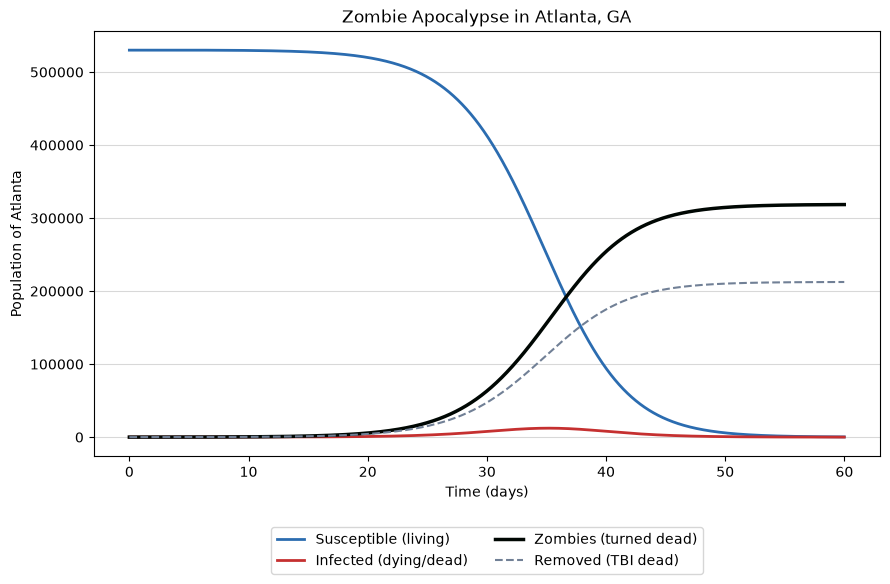

In [54]:
# Initialize your model for Atlanta
atlanta_model = Zombie_Apocalypse(
    initial_status=start,
    beta=0.5,        # Adjusted for a real outbreak spread rate 
    alpha=0.2,       # Combat kill rate 
    birth=0.00007,   # Atlanta birth rate
    delta=0.00003,    # Intervention / mercy kills
    model_function='latent_zombies'
)

time, status = atlanta_model.euler_solver(delta_t=0.01, T_max=60.0)
plot(status, time)

100%|██████████| 5999/5999 [00:01<00:00, 5486.38it/s]


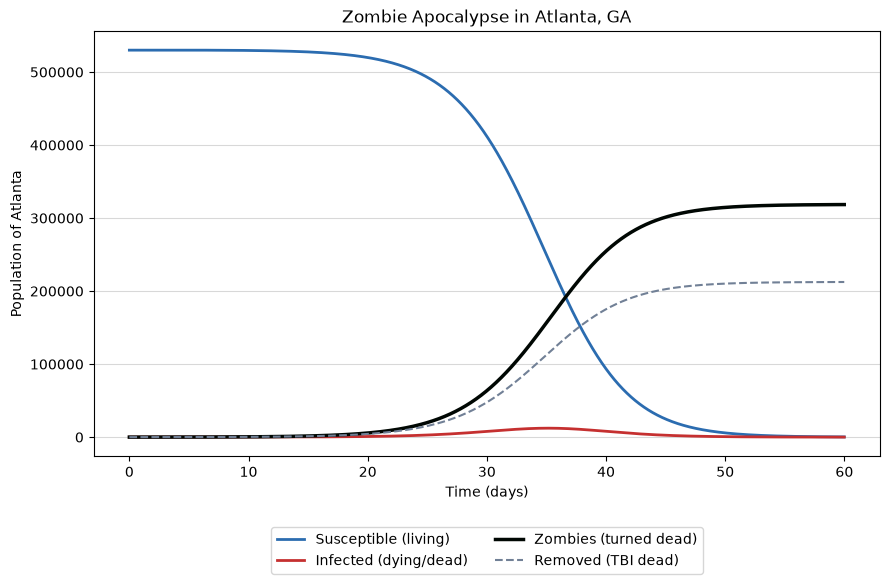

In [56]:
# Run using RK4 for rock-solid stability over 90 days
time, results = atlanta_model.RK4_solver(delta_t=0.01, T_max=60.0)
plot(results, time)
